<a href="https://colab.research.google.com/github/Temmy-bit/computer-vision-lab/blob/main/Image_classifier_livestream.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Loading The Necessary Dependencies


In [ ]:
import pandas as pd
import numpy as np
import os
import random
import albumentations as A
import timm
from fastai.vision.all import *
from sklearn.model_selection import StratifiedKFold
from fastai.metrics import F1Score,accuracy
import gc
import torch
from sklearn.metrics import f1_score

import warnings
warnings.filterwarnings('ignore')


#### Setting Seed For Reproducibility

In [ ]:
def random_seed(seed_value, use_cuda):
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    random.seed(seed_value)
    if use_cuda:
        torch.cuda.manual_seed(seed_value)
        torch.cuda.manual_seed_all(seed_value)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

random_seed(42, True)

### Load The Data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
PATH = "/content/drive/MyDrive/landlside_detection/"
TRAIN_IMAGE_PATH = "/content/drive/MyDrive/landlside_detection/composite_images/train/nir_green_blue/"
TEST_IMAGE_PATH = "/content/drive/MyDrive/landlside_detection/composite_images/test/nir_green_blue/"
'nir', 'green', 'blue'
drop_ids = [
    "ID_Z29R76"
]
train = pd.read_csv(PATH + "Train.csv")
test_df = pd.read_csv(PATH + "Test.csv")
train['image_path'] = TRAIN_IMAGE_PATH + train['ID'] + '.png'
train = train[~train['ID'].isin(drop_ids)].reset_index(drop=True)
test_df['image_path'] = TEST_IMAGE_PATH + test_df['ID'] + '.png'
display(train.head(), test_df.head(), train.shape, test_df.shape)


,ID,label,image_path
0,ID_HUD1ST,1,/content/drive/MyDrive/landlside_detection/composite_images/train/nir_green_blue/ID_HUD1ST.png
1,ID_KGE2HY,1,/content/drive/MyDrive/landlside_detection/composite_images/train/nir_green_blue/ID_KGE2HY.png
2,ID_VHV9BL,1,/content/drive/MyDrive/landlside_detection/composite_images/train/nir_green_blue/ID_VHV9BL.png
3,ID_ZT0VEJ,0,/content/drive/MyDrive/landlside_detection/composite_images/train/nir_green_blue/ID_ZT0VEJ.png
4,ID_5NFXVY,0,/content/drive/MyDrive/landlside_detection/composite_images/train/nir_green_blue/ID_5NFXVY.png


,ID,image_path
0,ID_ICB8K9,/content/drive/MyDrive/landlside_detection/composite_images/test/nir_green_blue/ID_ICB8K9.png
1,ID_2D4AOJ,/content/drive/MyDrive/landlside_detection/composite_images/test/nir_green_blue/ID_2D4AOJ.png
2,ID_2TVPI0,/content/drive/MyDrive/landlside_detection/composite_images/test/nir_green_blue/ID_2TVPI0.png
3,ID_E05WIK,/content/drive/MyDrive/landlside_detection/composite_images/test/nir_green_blue/ID_E05WIK.png
4,ID_KKFDJO,/content/drive/MyDrive/landlside_detection/composite_images/test/nir_green_blue/ID_KKFDJO.png


(7146, 3)

(5398, 2)

In [ ]:
len(os.listdir(TRAIN_IMAGE_PATH)), train.shape

(7147, (7146, 3))

In [ ]:
set(train['image_path'].unique()) - set([f"{TRAIN_IMAGE_PATH}{path}" for path in os.listdir(TRAIN_IMAGE_PATH)])

set()

In [ ]:
train['image_path'].unique()[0],[f"{TRAIN_IMAGE_PATH}{path}" for path in os.listdir(TRAIN_IMAGE_PATH)][0]

('/content/drive/MyDrive/landlside_detection/composite_images/train/nir_green_blue/ID_HUD1ST.png',
 '/content/drive/MyDrive/landlside_detection/composite_images/train/nir_green_blue/ID_HW7BJW.png')

In [ ]:
train['label'].value_counts()

,count
label,
0,5891
1,1255


#### Setup The Config

In [ ]:
timm.list_models("beit*")

['beit3_base_patch16_224',
 'beit3_giant_patch14_224',
 'beit3_giant_patch14_336',
 'beit3_large_patch16_224',
 'beit_base_patch16_224',
 'beit_base_patch16_384',
 'beit_large_patch16_224',
 'beit_large_patch16_384',
 'beit_large_patch16_512',
 'beitv2_base_patch16_224',
 'beitv2_large_patch16_224']

In [ ]:
class Config:
  n_splits = 5
  seed = 42
  image_size = 224
  model_name = "beitv2_large_patch16_224.in1k_ft_in22k_in1k" #"convnext_small.fb_in22k_ft_in1k"  # convnext_large.fb_in22k_ft_in1k
  batch_size = 16
  epochs = 12
  tta = 5
  num_classes = 2
  # lr = 0.0002 #2e-4

CFG = Config()
CFG.n_splits

5

### Cross Validation

In [ ]:
skf = StratifiedKFold(n_splits=CFG.n_splits, shuffle=True, random_state=CFG.seed)
train['fold'] = -1
for fold, (train_idx, val_idx) in enumerate(skf.split(train, train['label'])):
  train.loc[val_idx, 'fold'] = fold
print(train['fold'].value_counts())

fold
0    1430
4    1429
2    1429
1    1429
3    1429
Name: count, dtype: int64


### Define Augmentation

In [ ]:
class AlbumentationsTransform(RandTransform):
  split_idx, order = None, 2
  def __init__(self, train_aug, valid_aug): store_attr()

  def before_call(self, b, split_idx):
    self.idx = split_idx

  def encodes(self, img: PILImage):
    if self.idx == 0:
      aug_img = self.train_aug(image=np.array(img))['image']
    else:
      aug_img = self.valid_aug(image=np.array(img))['image']
    return PILImage.create(aug_img)

In [ ]:
import albumentations
def get_train_aug(): return albumentations.Compose([
            albumentations.Resize(CFG.image_size, CFG.image_size), #Extra tip, use size that's suitable for the efficentNetwork you are using.
            albumentations.HorizontalFlip(p=0.5),
            albumentations.VerticalFlip(p=0.5),
            ], p=1.)



def get_valid_aug(): return albumentations.Compose([
            albumentations.Resize(CFG.image_size, CFG.image_size),
            ], p=1.0)

item_tfms = AlbumentationsTransform(get_train_aug(), get_valid_aug())
batch_tfms = [Normalize.from_stats(*imagenet_stats)]

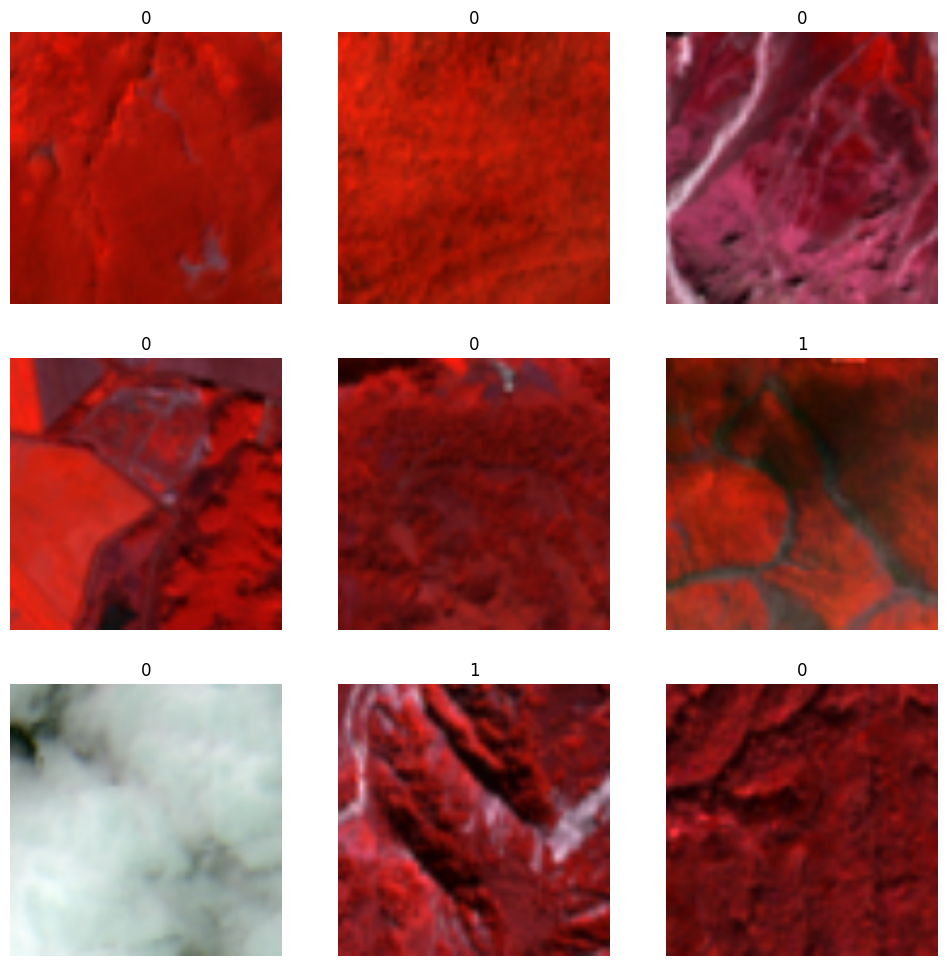

In [ ]:
def get_datablock(train, fold=0, bs = CFG.batch_size):
  return DataBlock(
      blocks = (ImageBlock, CategoryBlock),
      get_x = ColReader('image_path'),
      get_y = ColReader('label'),
      splitter = IndexSplitter(train[train['fold'] == fold].index),
      item_tfms = item_tfms,
      batch_tfms = batch_tfms
  ).dataloaders(train, bs=bs, seed= CFG.seed)

get_datablock(train).show_batch(figsize = (12,12))


### MODELLING

In [ ]:
test_df

,ID,image_path
0,ID_ICB8K9,/content/drive/MyDrive/landlside_detection/composite_images/test/nir_green_blue/ID_ICB8K9.png
1,ID_2D4AOJ,/content/drive/MyDrive/landlside_detection/composite_images/test/nir_green_blue/ID_2D4AOJ.png
2,ID_2TVPI0,/content/drive/MyDrive/landlside_detection/composite_images/test/nir_green_blue/ID_2TVPI0.png
3,ID_E05WIK,/content/drive/MyDrive/landlside_detection/composite_images/test/nir_green_blue/ID_E05WIK.png
4,ID_KKFDJO,/content/drive/MyDrive/landlside_detection/composite_images/test/nir_green_blue/ID_KKFDJO.png
...,...,...
5393,ID_44IBS3,/content/drive/MyDrive/landlside_detection/composite_images/test/nir_green_blue/ID_44IBS3.png
5394,ID_253HW0,/content/drive/MyDrive/landlside_detection/composite_images/test/nir_green_blue/ID_253HW0.png
5395,ID_10B6W6,/content/drive/MyDrive/landlside_detection/composite_images/test/nir_green_blue/ID_10B6W6.png
5396,ID_SB70CZ,/content/drive/MyDrive/landlside_detection/composite_images/test/nir_green_blue/ID_SB70CZ.png


In [ ]:
f1_score = F1Score(average='binary')
metrics = [accuracy, f1_score]

We are validating on fold : 0 and training on fold: [1, 2, 3, 4]
----------------------------------------------------------------------------------------------------


model.safetensors:   0%|          | 0.00/1.23G [00:00<?, ?B/s]

epoch,train_loss,valid_loss,accuracy,f1_score,time
0,0.369657,0.286114,0.897203,0.679739,03:29


Better model found at epoch 0 with f1_score value: 0.6797385620915033.


epoch,train_loss,valid_loss,accuracy,f1_score,time
0,0.220140,0.202039,0.912587,0.694377,05:12
1,0.211344,0.211431,0.925175,0.784708,05:12
2,0.165001,0.184351,0.930769,0.772414,05:12
3,0.147436,0.232530,0.916084,0.692308,05:10
4,0.110961,0.166082,0.941259,0.840304,05:10
5,0.069884,0.177347,0.933566,0.814815,05:12
6,0.056339,0.170934,0.951049,0.856557,05:10
7,0.036477,0.176474,0.955245,0.872510,05:12
8,0.020473,0.218230,0.946853,0.856061,05:12
9,0.005291,0.210371,0.958042,0.878543,05:10


Better model found at epoch 0 with f1_score value: 0.6943765281173594.
Better model found at epoch 1 with f1_score value: 0.7847082494969819.
Better model found at epoch 4 with f1_score value: 0.8403041825095057.
Better model found at epoch 6 with f1_score value: 0.8565573770491803.
Better model found at epoch 7 with f1_score value: 0.8725099601593626.
Better model found at epoch 9 with f1_score value: 0.8785425101214575.


... (17 outputs left out)

Better model found at epoch 0 with f1_score value: 0.7301587301587301.


epoch,train_loss,valid_loss,accuracy,f1_score,time
0,0.212591,0.130166,0.952414,0.863454,05:11
1,0.192868,0.147966,0.943317,0.817978,05:11
2,0.186937,0.132920,0.940518,0.824017,05:10
3,0.172781,0.128873,0.944717,0.841683,05:10
4,0.137329,0.180837,0.933520,0.768856,05:10
5,0.093344,0.124293,0.950315,0.845316,05:10
6,0.067874,0.171425,0.952414,0.847534,05:10
7,0.045282,0.120190,0.957313,0.873706,05:10
8,0.023451,0.114249,0.963611,0.895582,05:12
9,0.005549,0.157943,0.963611,0.887931,05:11


Better model found at epoch 0 with f1_score value: 0.8634538152610441.
Better model found at epoch 7 with f1_score value: 0.8737060041407867.
Better model found at epoch 8 with f1_score value: 0.8955823293172691.
Better model found at epoch 11 with f1_score value: 0.8977035490605428.


,ID,label,image_path,fold,oof_preds
0,ID_HUD1ST,1,/content/drive/MyDrive/landlside_detection/composite_images/train/nir_green_blue/ID_HUD1ST.png,4,"[0.027518505230545998, 0.9724815487861633]"
1,ID_KGE2HY,1,/content/drive/MyDrive/landlside_detection/composite_images/train/nir_green_blue/ID_KGE2HY.png,0,"[0.0005840795929543674, 0.9994159936904907]"
2,ID_VHV9BL,1,/content/drive/MyDrive/landlside_detection/composite_images/train/nir_green_blue/ID_VHV9BL.png,0,"[0.986528754234314, 0.013471268117427826]"
3,ID_ZT0VEJ,0,/content/drive/MyDrive/landlside_detection/composite_images/train/nir_green_blue/ID_ZT0VEJ.png,2,"[0.9999693632125854, 3.058804213651456e-05]"
4,ID_5NFXVY,0,/content/drive/MyDrive/landlside_detection/composite_images/train/nir_green_blue/ID_5NFXVY.png,1,"[0.9898279905319214, 0.010172078385949135]"


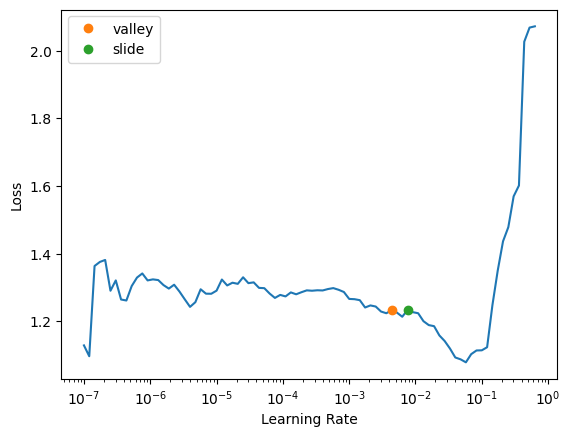

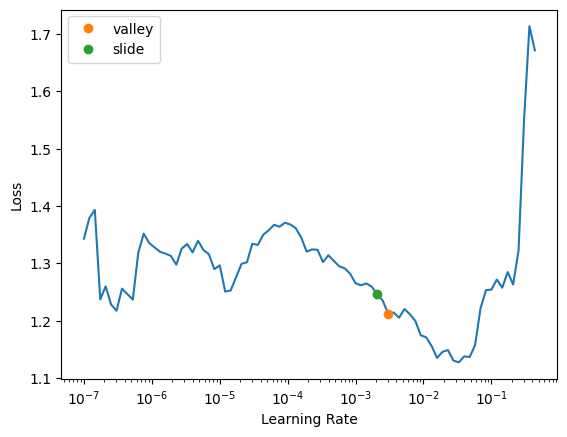

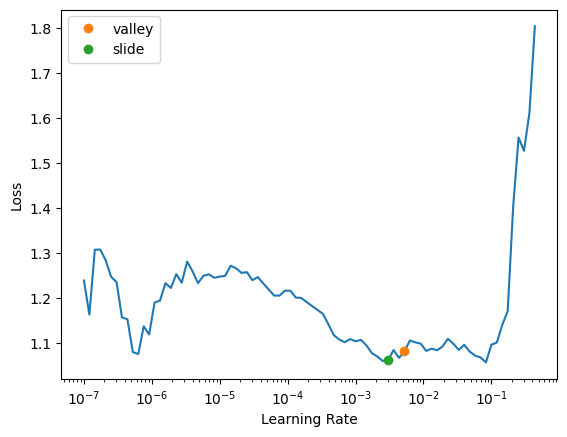

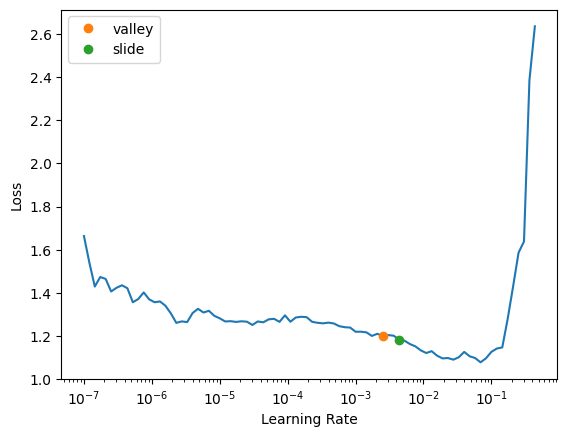

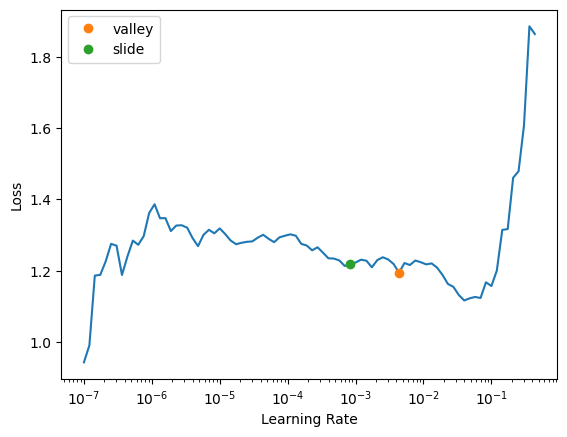

In [ ]:
oof_preds = np.zeros((len(train), CFG.num_classes))
all_preds = []

for fold in range(CFG.n_splits):
  print(f"We are validating on fold : {fold} and training on fold: {[i for i in range(CFG.n_splits) if i != fold]}")
  print("-"* 100)
  dls = get_datablock(train, fold, CFG.batch_size)
  learn = vision_learner(
      dls,
      CFG.model_name,
      loss_func = CrossEntropyLossFlat(),
      metrics = metrics,
      cbs = [SaveModelCallback(monitor = 'f1_score', comp = np.greater)]
  )
  _valley, _slide = learn.lr_find(suggest_funcs=(valley, slide))
  learn.fine_tune(CFG.epochs , _valley)

  # Validation
  val_idx = dls.valid.items.index
  val_dl = learn.dls.valid
  val_preds, _ = learn.tta(dl= val_dl, n=CFG.tta)#learn.get_preds(dl = val_dl)# learn.tta()
  oof_preds[val_idx] = val_preds.numpy()

  #Inference
  test_dl = learn.dls.test_dl(test_df)
  preds, _ = learn.tta(dl= test_dl, n=CFG.tta)#learn.get_preds(dl = test_dl)
  all_preds.append(preds.numpy())

  #clean up to free memory
  del learn, dls
  gc.collect()
  torch.cuda.empty_cache()



train['oof_preds'] = list(oof_preds)
display(train.head())


In [ ]:
from sklearn.metrics import f1_score

train['predicted_label'] = train['oof_preds'].apply(
    lambda preds: 1 if preds[1] > 0.5 else 0
)
y_true = train['label'].apply(int).values
y_pred = train['predicted_label'].apply(int).values

print("F1_Score", f1_score(y_true, y_pred))


F1_Score 0.8867155664221679


### Threshold Tuning
https://gpttutorpro.com/f1-machine-learning-essentials-optimizing-f1-score-with-threshold-tuning/

### Prepare the Submission

In [ ]:
all_preds_array = np.array([pred for pred in all_preds ])
mean_test_preds = all_preds_array.mean(axis = 0)
len(mean_test_preds)

5398

In [ ]:
np.argmax(mean_test_preds, axis = 1)

array([0, 0, 0, ..., 0, 0, 0])

In [ ]:
test_df['label'] = np.argmax(mean_test_preds, axis = 1)
test_df['label'].head()

,label
0,0
1,0
2,0
3,0
4,0


In [ ]:
test_df['label'].value_counts()

,count
label,
0,4782
1,616


In [ ]:
sub = test_df[['ID', 'label']]
sub.columns = ['ID', 'target']
sub.head()

,ID,target
0,ID_ICB8K9,0
1,ID_2D4AOJ,0
2,ID_2TVPI0,0
3,ID_E05WIK,0
4,ID_KKFDJO,0


In [ ]:
sub.to_csv(f"Baseline_Livestream_{CFG.model_name}_all_folds.csv", index= False)

In [ ]:
#Save If you want to experiment with ensembling
test_df['probability'] = mean_test_preds[:, 1]
test_df.to_csv(PATH + f"test_df_with_results_{CFG.model_name}.csv", index = False)
train.to_csv(PATH + f"train_df_with_results_{CFG.model_name}.csv", index = False)

In [ ]:
from google.colab import files
files.download(f"Baseline_Livestream_{CFG.model_name}_all_folds.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
#copy the models directory to your google drive
os.makedirs(f"{PATH}{CFG.model_name}", exist_ok=True)
shutil.copytree("/content/models", f"{PATH}{CFG.model_name}", dirs_exist_ok=True)